# Конечный заход: короткий горизонт прогноза
## Париж, Шарль-де-Голль, LFPG, 09L

**Исследование 04, 15 января 2025, Approach Risk 1.1**

**37 кандидатов**, **35 воздушных судов**, **30 секунд номинального прогноза**, **300 ft контрольного прокси**

Насколько информативно продолжение текущего снижения и может ли компактная модель уточнить его на конечном участке захода?

В основе эксперимента – авиационная постановка: направление движения относительно оси ВПП, высота на согласованной настройке давления и доступная к моменту наблюдения динамика. Сначала проверяется прогноз, затем обсуждается его возможная роль в мониторинге. Фактический уход на второй круг требует отдельного подтверждения и отдельной задачи.

**Маршрут чтения:** постановка → 37 кандидатов → причинные признаки → обучение → независимая проверка → разбор заходов → исторические документы.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from IPython.display import display
from IPython.display import HTML

# Определяем папку аэропорта при запуске из нее или из notebooks
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
sys.path.insert(0, str(PROJECT / 'scripts'))
from lfpg_training import (select_cohort, split_cohort, build_examples, causal_features,
                           event_errors, summarize, paired_bootstrap, height_in_setting)
from lfpg_approach_audit import local_xy
DATA, REPORTS, FIGURES = BASE / 'data/2025-01-15', BASE / 'reports', BASE / 'figures'
ARTIFACTS = BASE / 'artifacts/training_04'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
protocol_path = PROJECT / 'configs/lfpg_09l_training.json'
protocol = json.loads(protocol_path.read_text(encoding='utf-8'))
for relative_path, expected_hash in protocol['inputs_sha256'].items():
    with (BASE / relative_path).open('rb') as stream:
        assert hashlib.file_digest(stream, 'sha256').hexdigest() == expected_hash
events = pd.read_csv(REPORTS / '03_event_candidates.csv')
points = pd.read_parquet(DATA / 'event_candidate_points.parquet')
geometry = pd.read_csv(REPORTS / '03_runway_geometry.csv')
notam = json.loads((REPORTS / '04_notam_09l_status.json').read_text(encoding='utf-8'))
notam_example = json.loads((REPORTS / '04_notam_09l_example.json').read_text(encoding='utf-8'))
assert points.utc.ge(pd.Timestamp('2025-01-15', tz='UTC')).all()
assert points.utc.lt(pd.Timestamp('2025-01-16', tz='UTC')).all()
assert not notam['historical_notam_attached']

# Единая исследовательская палитра для всех диаграмм
RED, GREEN, INK, GREY = '#D65A4A', '#00897B', '#25343B', '#829198'
COLORS = {'train': GREEN, 'validation': '#80CBC4', 'test': RED}
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 13,
    'axes.labelcolor': INK, 'text.color': INK, 'axes.edgecolor': '#B7C3C8',
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'svg.hashsalt': 'lfpg-09l-training-04'})

def savefig(fig, name):
    fig.savefig(FIGURES / (name + '.png'), dpi=180, bbox_inches='tight')
    svg_path = FIGURES / (name + '.svg')
    fig.savefig(svg_path, bbox_inches='tight', metadata={'Date': None})
    svg_path.write_text(chr(10).join(line.rstrip() for line in
        svg_path.read_text(encoding='utf-8').splitlines()) + chr(10), encoding='utf-8')
    plt.show()

def table(frame, decimals=2):
    numeric = frame.select_dtypes(include='number').columns
    formats = {col: '{:.0f}' if pd.api.types.is_integer_dtype(frame[col])
               else '{:.' + str(decimals) + 'f}' for col in numeric}
    display(frame.style.format(formats)
        .hide(axis='index').set_properties(**{'text-align': 'left', 'padding': '8px'})
        .set_table_styles([{'selector': 'th', 'props': [('background-color', '#E8F3F1'),
                                                     ('color', INK), ('padding', '8px')]}]))

def panel(title, body, color=GREEN):
    display(HTML(f'<div style="border-left:5px solid {color};padding:14px 20px;'
        f'background:#F4F8F7;margin:12px 0;color:{INK}"><b>{title}</b><br>{body}</div>'))

print('Данные загружены локально; параметры и границы эксперимента зафиксированы')

Данные загружены локально; параметры и границы эксперимента зафиксированы


## 01 Авиационная постановка

На коротком горизонте естественная точка сравнения – сохранение текущей вертикальной скорости. Если она составляет −700 ft/min, за 30 с ожидается снижение на 350 ft. Модель должна показать, добавляют ли предыдущие наблюдения и геометрия конечного участка полезное уточнение.

$$\widehat h_{CV}(t+\tau)=h_{Q(t)}(t)+c[Q(t)]\,V_z(t)\,\tau/60$$
$$\widehat h_{ML}(t+\tau)=\widehat h_{CV}(t+\tau)+f_\alpha(X_{\leq t},\tau)$$

$h_{Q(t)}$ – барометрический прокси высоты над отметкой аэродрома на текущем доступном QNH; $c=(1013,25/QNH)^k$ – коэффициент перенастройки; $V_z$ – барометрическая вертикальная скорость в ft/min. Модель Ridge обучается остаточной ошибке физического прогноза.

**Что известно:** сохраненные ADS-B trace, исторический справочник геометрии, METAR. **Что еще не подтверждено:** реальный захват ILS, истинная высота над поверхностью, эксплуатационный исход и архивный комплект NOTAM.

Высотный прогноз – первый обучаемый компонент. Горизонтальная геометрия пока входит в признаки; отдельный прогноз бокового положения и оценка риска будут следующими исследованиями.

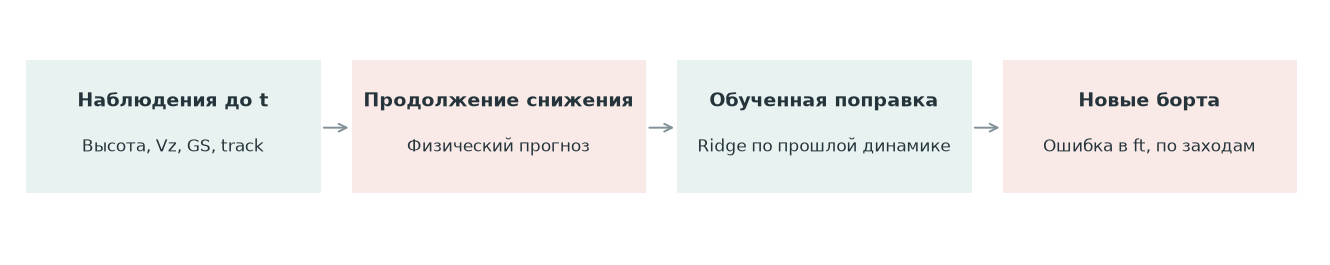

In [2]:
# Показываем последовательность решения в одном визуальном кадре
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.axis('off')
steps = [('Наблюдения до t', 'Высота, Vz, GS, track'),
         ('Продолжение снижения', 'Физический прогноз'),
         ('Обученная поправка', 'Ridge по прошлой динамике'),
         ('Новые борта', 'Ошибка в ft, по заходам')]
for i, (title, detail) in enumerate(steps):
    x = .01 + i * .25
    ax.add_patch(plt.Rectangle((x, .25), .225, .55, transform=ax.transAxes,
                              color='#E8F3F1' if i % 2 == 0 else '#F9EAE7'))
    ax.text(x + .112, .61, title, transform=ax.transAxes, ha='center', fontsize=10, weight='bold')
    ax.text(x + .112, .42, detail, transform=ax.transAxes, ha='center', fontsize=8.5)
    if i < 3:
        ax.annotate('', xy=(x + .25, .52), xytext=(x + .225, .52), xycoords='axes fraction',
                    arrowprops={'arrowstyle': '->', 'color': GREY})
savefig(fig, '04_research_flow')

## 02 Группа: 37 кандидатов 09L

Кандидаты наследуются из независимого геометрического аудита этапа 03: прибытие в коридоре продолжения 09L, наблюдаемое пересечение прокси 300 ft, минимум 60 с покрытия до границы и отсутствие конкурирующего назначения на параллельную полосу.

Для этого эксперимента принят максимальный разрыв **30 с** вместо строгих 15 с. Решение увеличивает группу с 12 до 37 и принято до просмотра ошибок моделей. Разрывы отражают разрешение сохраненного архива; происхождение прореживания и потерь приема не разделено.

Группа отобрана ретроспективно по наблюдаемости. Это условие построения исследовательского набора, а не алгоритм обнаружения захода в реальном времени. Не прошедшие отбор траектории, ранние уходы и менее наблюдаемые участки не представлены.

split,events,aircraft,median_precontrol_s
train,21,21,186.40
validation,8,7,197.00
test,8,7,188.05


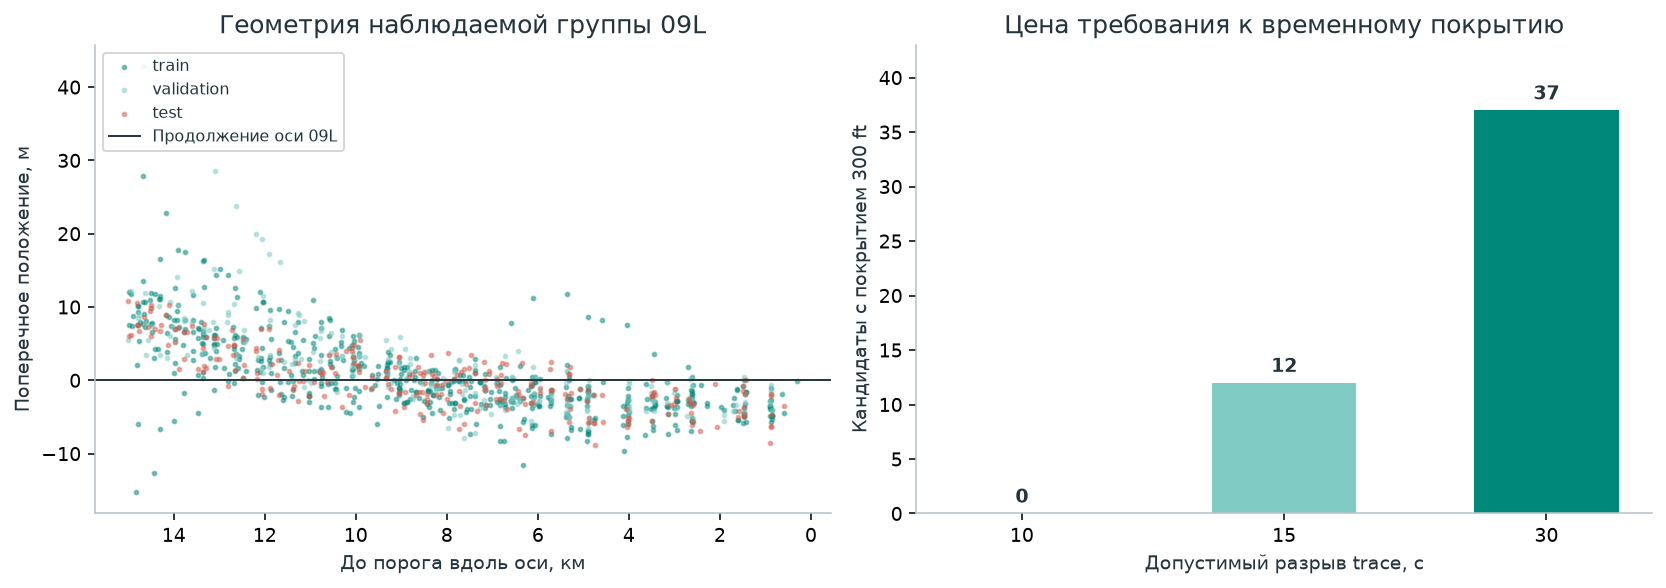

In [3]:
# Фиксируем все 37 кандидатов и распределение целых групп воздушных судов
cohort = split_cohort(select_cohort(events, protocol), protocol)
cohort['start_utc'] = pd.to_datetime(cohort.start_time, unit='s', utc=True)
cohort.to_csv(REPORTS / '04_cohort_and_split.csv', index=False)
split_summary = cohort.groupby('split').agg(events=('event_id', 'size'),
    aircraft=('icao24', 'nunique'), median_precontrol_s=('precontrol_span_s', 'median'))
split_summary = split_summary.reindex(['train', 'validation', 'test']).reset_index()
table(split_summary)
assert len(cohort) == 37 and cohort.icao24.nunique() == 35
panel('Отбор зафиксирован', '37 заходов-кандидатов, 35 бортов, 1 аэропорт, 1 сутки, 1 направление ВПП')

# Геометрия относится к выбранной группе, а не ко всем прибытиям суток
runway = geometry.loc[geometry.runway.eq('09L')].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for split in ['train', 'validation', 'test']:
    subset = points.loc[points.event_id.isin(cohort.loc[cohort.split.eq(split), 'event_id'])]
    axes[0].scatter(subset.distance_to_threshold_m / 1000, subset.lateral_m,
                    s=4, alpha=.45, c=COLORS[split], label=split)
axes[0].axhline(0, color=INK, lw=1, label='Продолжение оси 09L')
axes[0].set(title='Геометрия наблюдаемой группы 09L', xlabel='До порога вдоль оси, км',
            ylabel='Поперечное положение, м')
axes[0].invert_xaxis()
axes[0].legend(fontsize=8, loc='upper left')
gaps = pd.read_csv(REPORTS / '03_gap_sensitivity.csv')
axes[1].bar(gaps.max_gap_s.astype(str), gaps.coverage300_candidates,
            color=[GREY, '#80CBC4', GREEN], width=.55)
for x, value in enumerate(gaps.coverage300_candidates):
    axes[1].text(x, value + 1, str(value), ha='center', weight='bold')
axes[1].set(title='Цена требования к временному покрытию', xlabel='Допустимый разрыв trace, с',
            ylabel='Кандидаты с покрытием 300 ft', ylim=(0, 43))
fig.tight_layout()
savefig(fig, '04_cohort_and_coverage')

## 03 Причинность: какую информацию видит модель

В момент $t$ признаки строятся только по префиксу траектории до $t$ включительно. Предыдущая точка выбирается из интервала 5–30 с в прошлом. Геометрическая вертикальная скорость исключается: ее нельзя смешивать с барометрическим высотным target.

Будущая цель – **реально сохраненное наблюдение**, ближайшее к $t+30$ с, с допуском ±3 с. Интерполяции цели и признаков нет. Точный горизонт 27–33 с задается как запрос модели и используется обеими моделями. Следовательно, результат относится к проверке на доступных наблюдениях около 30 с; точный фиксированный горизонт 30 с пока не проверен.

Будущая барометрическая высота перенастраивается на **QNH, доступный в момент прогноза**. Это сохраняет одну шкалу давления и исключает использование будущего METAR в target. QNH задержан условно на 15 минут; исходное received_at неизвестно. Поправка не устраняет температурные и приборные ошибки.

Точки начала и цели строго предшествуют первому наблюдению ниже контрольной границы и имеют прокси выше 300 ft. Последние секунды перед границей закономерно не дают цели внутри окна. Поэтому точность прогнозов из самого нижнего участка перед 300 ft не проверена; фактический диапазон высот начала прогноза приведен в таблице.

Номер борта, идентификатор захода, будущая высота, время окончания захода и качество будущего покрытия не входят в признаки.

In [4]:
# Строим пары наблюдений без интерполяции и фиксируем причины потерь
examples, sample_audit = build_examples(cohort, points, geometry, protocol)
examples.to_parquet(DATA / 'training_04_examples.parquet', index=False)
sample_audit.to_csv(REPORTS / '04_sample_construction_audit.csv', index=False)
counts = examples.groupby('split').agg(events=('event_id', 'nunique'),
    aircraft=('icao24', 'nunique'), pairs=('event_id', 'size'),
    horizon_min_s=('horizon_s', 'min'), horizon_median_s=('horizon_s', 'median'),
    horizon_max_s=('horizon_s', 'max')).reindex(['train', 'validation', 'test']).reset_index()
table(counts)
height_coverage = examples.groupby('split').agg(
    origin_min_ft=('height_ft', 'min'), origin_max_ft=('height_ft', 'max'),
    target_min_ft=('target_height_ft', 'min')).reindex(['train', 'validation', 'test']).reset_index()
height_coverage.to_csv(REPORTS / '04_forecast_height_coverage.csv', index=False)
table(height_coverage)
print('Все 37 кандидатов представлены:', examples.event_id.nunique() == 37)
print('Целей с изменением QNH между наблюдениями:', int(examples.origin_qnh_hpa.ne(examples.target_qnh_hpa).sum()))
losses = sample_audit[['precontrol_points', 'no_target_at_horizon',
    'missing_causal_features', 'target_below_control_in_origin_qnh', 'examples']].sum()
table(losses.rename_axis('Этап / причина').reset_index(name='Наблюдений'), decimals=0)

feature_dictionary = pd.DataFrame([
    ('height_ft', 'ft', 'Высотный прокси на текущем QNH'),
    ('vertical_rate_fps', 'ft/s', 'Текущая барометрическая Vz с коэффициентом QNH'),
    ('past_height_rate_fps', 'ft/s', 'Изменение исходной высоты по предыдущей точке, текущий QNH'),
    ('speed_knots', 'knots', 'Скорость над землей, не IAS'),
    ('distance_m', 'm', 'Расстояние до порога вдоль продолжения оси'),
    ('lateral_m', 'm', 'Знаковое поперечное положение относительно оси'),
    ('heading_error_deg', 'deg', 'Track относительно вычисленного направления ВПП'),
    ('past_gap_s', 's', 'Возраст выбранного предыдущего наблюдения'),
    ('horizon_s', 's', 'Заданный горизонт запроса модели')],
    columns=['Признак', 'Единица', 'Авиационный смысл'])
feature_dictionary.to_csv(REPORTS / '04_feature_dictionary.csv', index=False)
table(feature_dictionary)

split,events,aircraft,pairs,horizon_min_s,horizon_median_s,horizon_max_s
train,21,21,347,27.02,30.15,32.99
validation,8,7,128,27.04,30.03,32.99
test,8,7,158,27.20,30.14,32.83


split,origin_min_ft,origin_max_ft,target_min_ft
train,639.38,2632.05,315.57
validation,639.38,2583.55,315.57
test,665.96,2658.26,317.31


Этап / причина,Наблюдений
precontrol_points,1006
no_target_at_horizon,320
missing_causal_features,53
target_below_control_in_origin_qnh,0
examples,633


Признак,Единица,Авиационный смысл
height_ft,ft,Высотный прокси на текущем QNH
vertical_rate_fps,ft/s,Текущая барометрическая Vz с коэффициентом QNH
past_height_rate_fps,ft/s,"Изменение исходной высоты по предыдущей точке, текущий QNH"
speed_knots,knots,"Скорость над землей, не IAS"
distance_m,m,Расстояние до порога вдоль продолжения оси
lateral_m,m,Знаковое поперечное положение относительно оси
heading_error_deg,deg,Track относительно вычисленного направления ВПП
past_gap_s,s,Возраст выбранного предыдущего наблюдения
horizon_s,s,Заданный горизонт запроса модели


Все 37 кандидатов представлены: True
Целей с изменением QNH между наблюдениями: 3


## 04 Независимая проверка: целые борта

Разделение фиксируется по **ICAO24**: 60% групп для обучения, 20% для выбора регуляризации и 20% для финальной проверки. Два повторных захода того же борта остаются в одной части. Seed и список групп сохраняются.

Это случайное разделение бортов внутри одних суток, а не испытание на будущем дне. Строки одной траектории коррелированы. Поэтому основная метрика – среднее MAE по заходам с равным весом каждого захода. При обучении сумма весов наблюдений каждого захода также одинакова.

Стандартизация обучается только на train. Единственный подбираемый параметр – сила регуляризации Ridge из пяти заранее заданных значений. Выбор идет по validation; test сохраняется для проверки выбранной модели. После выбора модель не переобучается на validation.

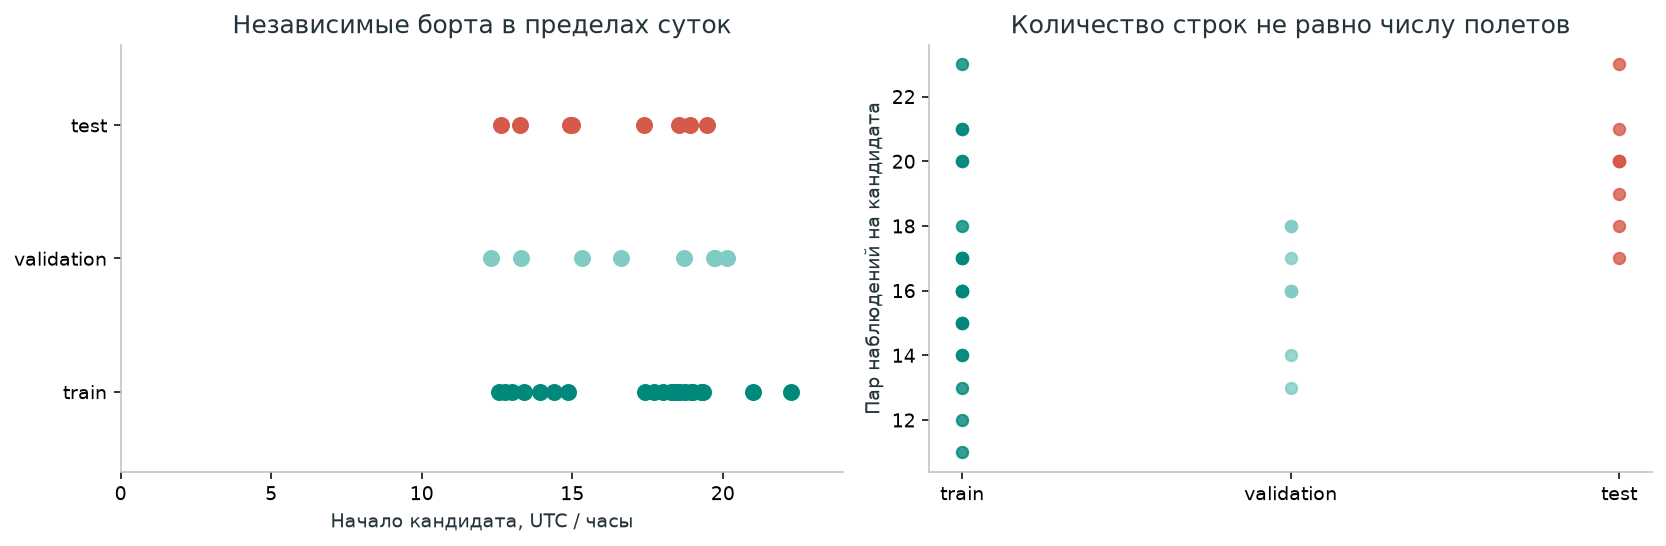

In [5]:
# Проверяем отсутствие общих бортов и общих исходных треков между частями
for key in ['icao24', 'trace_id', 'event_id']:
    assert examples.groupby(key).split.nunique().eq(1).all()
train = examples.loc[examples.split.eq('train')].copy()
validation = examples.loc[examples.split.eq('validation')].copy()
test = examples.loc[examples.split.eq('test')].copy()
FEATURES = protocol['features']
assert np.isfinite(examples[FEATURES].to_numpy()).all()
assert not set(FEATURES) & {'icao24', 'event_id', 'target_height_ft', 'target_time', 'boundary_time'}
weights = 1 / train.groupby('event_id').event_id.transform('size')
weights = weights * len(train) / weights.sum()
assert np.allclose(weights.groupby(train.event_id).sum(), len(train) / train.event_id.nunique())

# Показываем распределение по времени без заявления о хронологическом разделении
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, split in enumerate(['train', 'validation', 'test']):
    selected = cohort.loc[cohort.split.eq(split)]
    hours = selected.start_utc.dt.hour + selected.start_utc.dt.minute / 60
    axes[0].scatter(hours, np.full(len(selected), i), s=60, c=COLORS[split], label=split)
axes[0].set(yticks=[0, 1, 2], yticklabels=['train', 'validation', 'test'], ylim=(-.6, 2.6),
            xlim=(0, 24), xlabel='Начало кандидата, UTC / часы', title='Независимые борта в пределах суток')
for i, split in enumerate(['train', 'validation', 'test']):
    values = sample_audit.loc[sample_audit.split.eq(split), 'examples']
    axes[1].scatter(np.full(len(values), i), values, s=35, c=COLORS[split], alpha=.8)
axes[1].set(xticks=[0, 1, 2], xticklabels=['train', 'validation', 'test'],
            ylabel='Пар наблюдений на кандидата', title='Количество строк не равно числу полетов')
fig.tight_layout()
savefig(fig, '04_group_split')

## 05 Обучение поправки к физическому прогнозу

Выбран Ridge: линейная поправка с L2-регуляризацией. На малой группе она дает проверяемую модель с ограниченным числом параметров и позволяет оценить вклад признаков без большого пространства настройки.

Обучаемая величина $r=h_{target}-\widehat h_{CV}$. Каждый кандидат имеет равный суммарный вес. Пять моделей обучаются только на train; validation определяет одно значение alpha. Дальнейшие решения о признаках и гиперпараметрах по test не принимаются.

Документация: [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).

In [6]:
# Подбираем только регуляризацию и сохраняем все результаты validation
models, tuning_rows = {}, []
for alpha in protocol['ridge_alphas']:
    model = Pipeline([('scale', StandardScaler()), ('ridge', Ridge(alpha=alpha, solver='svd'))])
    model.fit(train[FEATURES], train.residual_ft, scale__sample_weight=weights,
              ridge__sample_weight=weights)
    forecast = validation.baseline_ft + model.predict(validation[FEATURES])
    result = summarize(validation, forecast, 'Ridge correction')
    result['alpha'] = alpha
    tuning_rows.append(result)
    models[alpha] = model
tuning = pd.DataFrame(tuning_rows).sort_values(['macro_mae_ft', 'alpha'])
selected_alpha = float(tuning.iloc[0].alpha)
selected_model = models[selected_alpha]
tuning.to_csv(REPORTS / '04_validation_tuning.csv', index=False)
table(tuning[['alpha', 'macro_mae_ft', 'macro_rmse_ft', 'macro_bias_ft']])
validation_baseline = summarize(validation, validation.baseline_ft, 'Constant vertical rate')
validation_selected = summarize(validation,
    validation.baseline_ft + selected_model.predict(validation[FEATURES]), 'Ridge correction')
validation_metrics = pd.DataFrame([validation_baseline, validation_selected])
validation_metrics.to_csv(REPORTS / '04_validation_metrics.csv', index=False)
table(validation_metrics[['model', 'events', 'examples', 'macro_mae_ft', 'macro_rmse_ft']])
print('Выбранная регуляризация:', selected_alpha)

# Проверяем, что обученная стандартизация соответствует только train
expected_mean = np.average(train[FEATURES].to_numpy(), axis=0, weights=weights)
assert np.allclose(selected_model.named_steps['scale'].mean_, expected_mean)
joblib.dump({'model': selected_model, 'features': FEATURES, 'protocol': protocol,
             'selected_alpha': selected_alpha}, ARTIFACTS / 'altitude_residual_ridge.joblib')
print('Обученная модель сохранена в игнорируемой папке artifacts')

alpha,macro_mae_ft,macro_rmse_ft,macro_bias_ft
0.10,16.65,21.27,-8.17
1.00,17.05,21.94,-8.34
10.00,17.28,22.35,-8.25
100.00,23.61,30.71,-7.06
1000.00,35.65,47.87,-2.75


model,events,examples,macro_mae_ft,macro_rmse_ft
Constant vertical rate,8,128,48.60,63.76
Ridge correction,8,128,16.65,21.27


Выбранная регуляризация: 0.1
Обученная модель сохранена в игнорируемой папке artifacts


## 06 Контроль причинности и целевой шкалы

Проверяем четыре свойства, которые прямо влияют на достоверность результата: признаки совпадают при удалении будущего; подмена будущих измерений не меняет доступные признаки; baseline и target используют одну шкалу текущего QNH; общие борта и треки отсутствуют между частями.

Будущие точки используются только для построения target и ретроспективного отбора наблюдаемой группы. Время target задает горизонт запроса, но будущие значения не поступают в модель. Такая проверка не подтверждает качество исходного приемника или реальную историческую доступность METAR.

In [7]:
# Проверяем префикс признаков для каждого обучающего и контрольного примера
bearing = float(geometry.loc[geometry.runway.eq('09L'), 'bearing_deg'].iloc[0])
causal_checks = 0
for event_id, group_examples in examples.groupby('event_id'):
    original = points.loc[points.event_id.eq(event_id)].sort_values('time')
    for row in group_examples.itertuples(index=False):
        prefix = original.loc[original.time.le(row.origin_time)]
        rebuilt = causal_features(prefix, row.horizon_s, bearing, protocol)
        assert np.allclose([rebuilt[name] for name in FEATURES], [getattr(row, name) for name in FEATURES])
        causal_checks += 1
    row = group_examples.iloc[0]
    mutated = original.copy()
    future = mutated.time.gt(row.origin_time)
    mutated.loc[future, ['altitude_ft', 'vertical_rate_fpm', 'speed_knots', 'qnh_hpa']] = 999999
    changed = causal_features(mutated.loc[mutated.time.le(row.origin_time)], row.horizon_s, bearing, protocol)
    assert np.allclose([changed[name] for name in FEATURES], row[FEATURES].astype(float).to_numpy())

# Независимо восстанавливаем target и проверяем точное совпадение времени наблюдения
target_checks = 0
for row in examples.itertuples(index=False):
    target = points.loc[points.event_id.eq(row.event_id) & points.time.eq(row.target_time)]
    assert len(target) == 1
    height = height_in_setting(float(target.altitude_ft.iloc[0]), row.origin_qnh_hpa,
                              protocol['airport_elevation_ft'])
    assert np.isclose(height, row.target_height_ft)
    assert np.isclose(row.baseline_ft, row.height_ft + row.vertical_rate_fps * row.horizon_s)
    target_checks += 1
checks = {'causal_prefix_checks': causal_checks, 'future_mutation_event_checks': len(cohort),
    'observed_target_checks': target_checks, 'group_overlap': False,
    'target_interpolation': False, 'future_weather_used_in_target': False,
    'train_only_scaler_verified': True}
(REPORTS / '04_integrity_checks.json').write_text(json.dumps(checks, ensure_ascii=False, indent=2), encoding='utf-8')
panel('Контроль данных пройден', f'{causal_checks} префиксов признаков, '
      f'{target_checks} наблюдаемых целей, подмена будущего проверена для 37 кандидатов')

## 07 Проверка выбранной модели

Основная метрика **macro MAE**: сначала средняя абсолютная ошибка каждого захода, затем равновесное среднее по заходам. Macro RMSE вычисляется из среднего квадратов ошибок по заходам. Дополнительно показаны построчная MAE, 95-й процентиль абсолютной ошибки и знаковое смещение.

Для разности MAE выполняется парный bootstrap целыми бортами; повторные заходы сохраняются вместе. Интервал условен для этой малой группы, одного дня и одной фиксированной модели. Он не оценивает переносимость на другие дни, погоду или аэропорты.

**Положительная разность Ridge − baseline означает ухудшение.** Высотная ошибка в ft не превращается в вероятность GoA или показатель безопасности.

model,events,examples,macro_mae_ft,macro_rmse_ft,point_mae_ft,point_p95_abs_ft,macro_bias_ft
Constant vertical rate,8,158,67.75,96.17,67.85,182.38,-28.86
Ridge correction,8,158,23.71,31.95,23.47,61.71,-5.43


resampling_unit,independent_groups,repetitions,ridge_minus_baseline_mae_ft,conditional_interval_2_5_ft,conditional_interval_97_5_ft
icao24,7,5000,-44.04,-57.81,-29.20


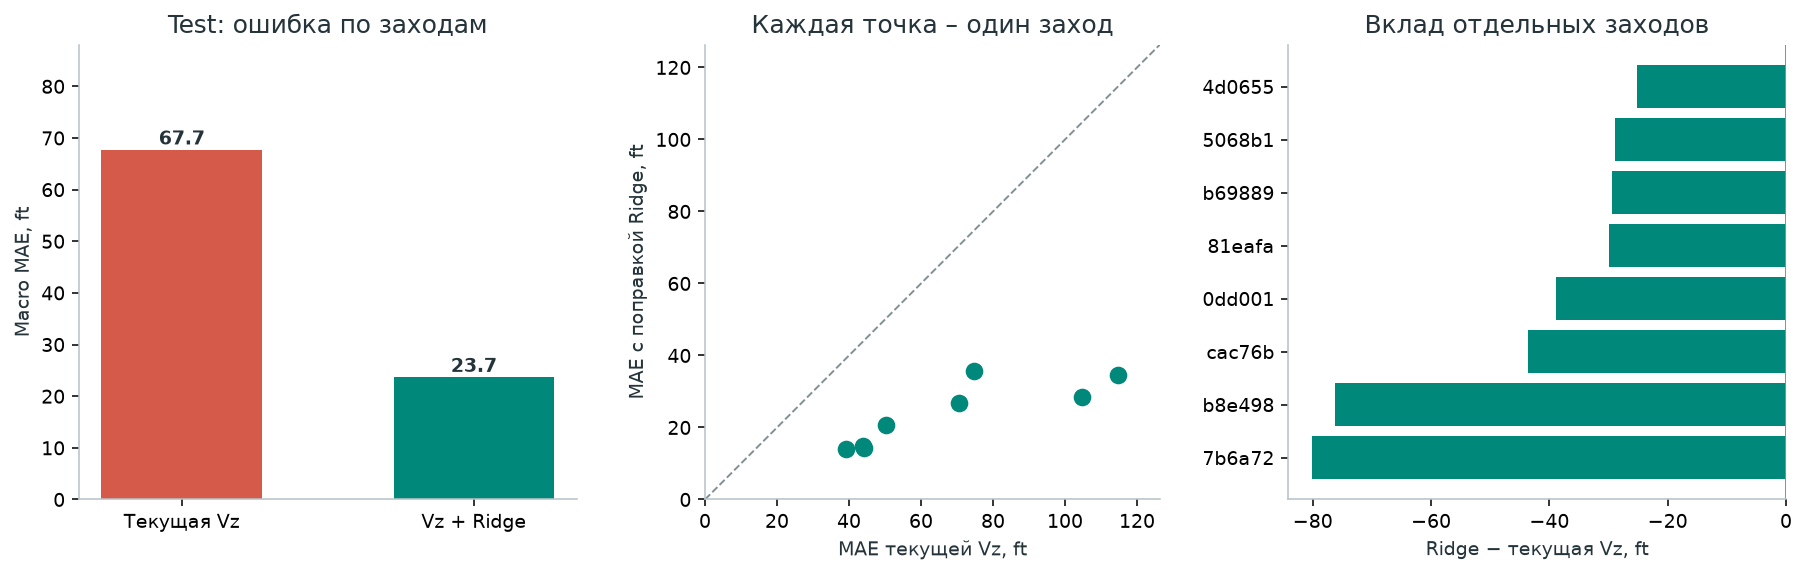

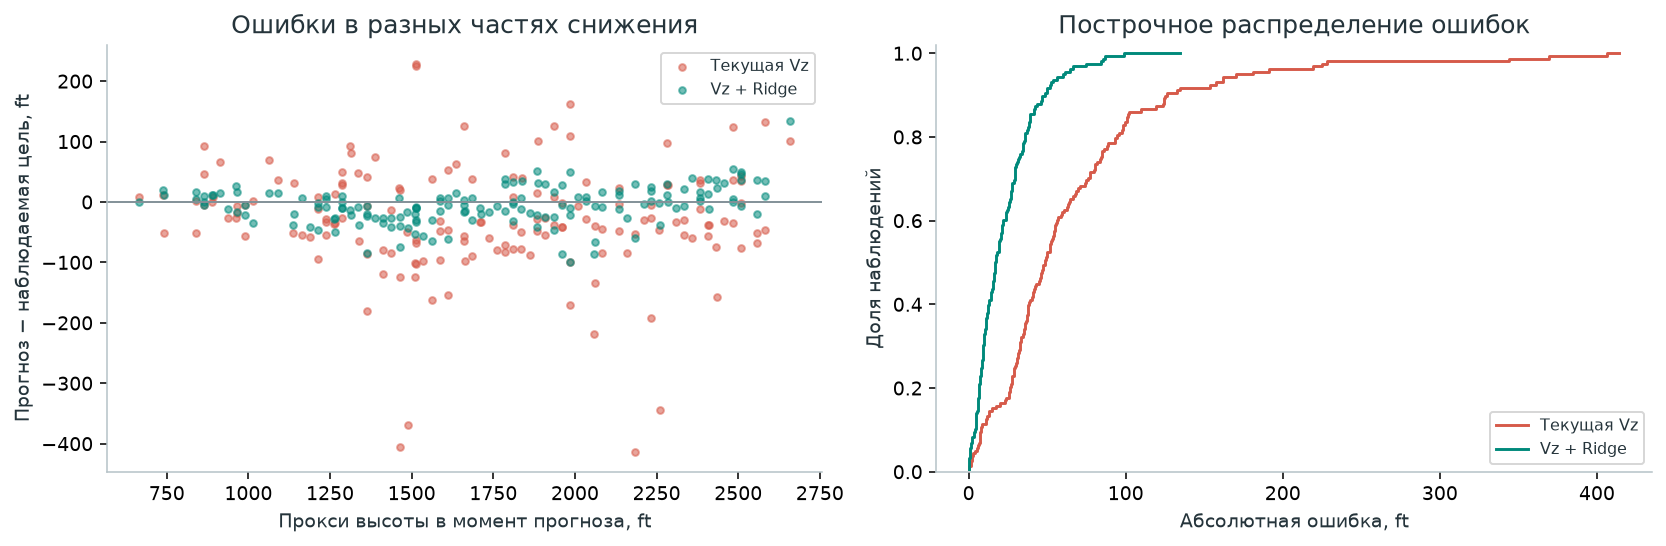

In [8]:
# Открываем test только после фиксации alpha и завершения проверок
test_prediction = test.baseline_ft + selected_model.predict(test[FEATURES])
test_metrics = pd.DataFrame([
    summarize(test, test.baseline_ft, 'Constant vertical rate'),
    summarize(test, test_prediction, 'Ridge correction')])
test_metrics.to_csv(REPORTS / '04_test_metrics.csv', index=False)
table(test_metrics)
test_event_metrics = pd.concat([
    event_errors(test, test.baseline_ft, 'Constant vertical rate'),
    event_errors(test, test_prediction, 'Ridge correction')], ignore_index=True)
test_event_metrics.to_csv(REPORTS / '04_test_event_metrics.csv', index=False)
interval = paired_bootstrap(test_event_metrics, protocol['seed'] + 2,
                           protocol['bootstrap_repetitions'])
(REPORTS / '04_paired_bootstrap.json').write_text(json.dumps(interval, indent=2), encoding='utf-8')
table(pd.DataFrame([interval]))
test = test.copy()
test['ridge_ft'] = test_prediction.to_numpy()
test.to_parquet(DATA / 'training_04_test_predictions.parquet', index=False)
train_metrics = pd.DataFrame([
    summarize(train, train.baseline_ft, 'Constant vertical rate'),
    summarize(train, train.baseline_ft + selected_model.predict(train[FEATURES]), 'Ridge correction')])
train_metrics.to_csv(REPORTS / '04_train_diagnostic_metrics.csv', index=False)

# Сопоставляем ошибки без изменения протокола по результату test
baseline_mae = float(test_metrics.loc[test_metrics.model.eq('Constant vertical rate'), 'macro_mae_ft'].iloc[0])
ridge_mae = float(test_metrics.loc[test_metrics.model.eq('Ridge correction'), 'macro_mae_ft'].iloc[0])
improvement_pct = 100 * (baseline_mae - ridge_mae) / baseline_mae
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
axes[0].bar(['Текущая Vz', 'Vz + Ridge'], [baseline_mae, ridge_mae], color=[RED, GREEN], width=.55)
for i, value in enumerate([baseline_mae, ridge_mae]):
    axes[0].text(i, value + 1, f'{value:.1f}', ha='center', weight='bold')
axes[0].set(title='Test: ошибка по заходам', ylabel='Macro MAE, ft',
            ylim=(0, max(baseline_mae, ridge_mae) * 1.3))
wide = test_event_metrics.pivot(index='event_id', columns='model', values='mae_ft')
maximum = wide.to_numpy().max() * 1.1
axes[1].scatter(wide['Constant vertical rate'], wide['Ridge correction'], c=GREEN, s=65)
axes[1].plot([0, maximum], [0, maximum], '--', color=GREY, lw=1)
axes[1].set(title='Каждая точка – один заход', xlabel='MAE текущей Vz, ft',
            ylabel='MAE с поправкой Ridge, ft', xlim=(0, maximum), ylim=(0, maximum))
axes[1].set_aspect('equal')
differences = (wide['Ridge correction'] - wide['Constant vertical rate']).sort_values()
axes[2].barh(np.arange(len(differences)), differences,
             color=[GREEN if value < 0 else RED for value in differences])
axes[2].axvline(0, color=GREY, lw=1)
axes[2].set(yticks=np.arange(len(differences)),
            yticklabels=[key[:6] for key in differences.index],
            title='Вклад отдельных заходов', xlabel='Ridge − текущая Vz, ft')
fig.tight_layout()
savefig(fig, '04_test_comparison')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label, color in [('baseline_ft', 'Текущая Vz', RED), ('ridge_ft', 'Vz + Ridge', GREEN)]:
    errors = test[column] - test.target_height_ft
    axes[0].scatter(test.height_ft, errors, s=12, c=color, alpha=.55, label=label)
    ordered = np.sort(np.abs(errors))
    axes[1].step(ordered, np.arange(1, len(ordered) + 1) / len(ordered), color=color, label=label)
axes[0].axhline(0, color=GREY, lw=1)
axes[0].set(title='Ошибки в разных частях снижения', xlabel='Прокси высоты в момент прогноза, ft',
            ylabel='Прогноз − наблюдаемая цель, ft')
axes[1].set(title='Построчное распределение ошибок', xlabel='Абсолютная ошибка, ft',
            ylabel='Доля наблюдений', ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, '04_error_structure')

## 08 Как модель вносит поправку

Коэффициенты показывают изменение поправки в ft при изменении признака на одно стандартное отклонение train, при фиксированных остальных признаках. Это описание обученной линейной модели. Коррелированные высота, удаление и вертикальная динамика не позволяют читать коэффициенты как независимые причинные эффекты.

Ниже показаны обучающие и контрольные ошибки рядом: разрыв между ними помогает увидеть предел малой выборки. Для выбора модели использован только validation.

split,model,events,macro_mae_ft,macro_rmse_ft
train,Constant vertical rate,21,48.74,64.20
train,Ridge correction,21,15.20,18.54
validation,Constant vertical rate,8,48.60,63.76
validation,Ridge correction,8,16.65,21.27
test,Constant vertical rate,8,67.75,96.17
test,Ridge correction,8,23.71,31.95


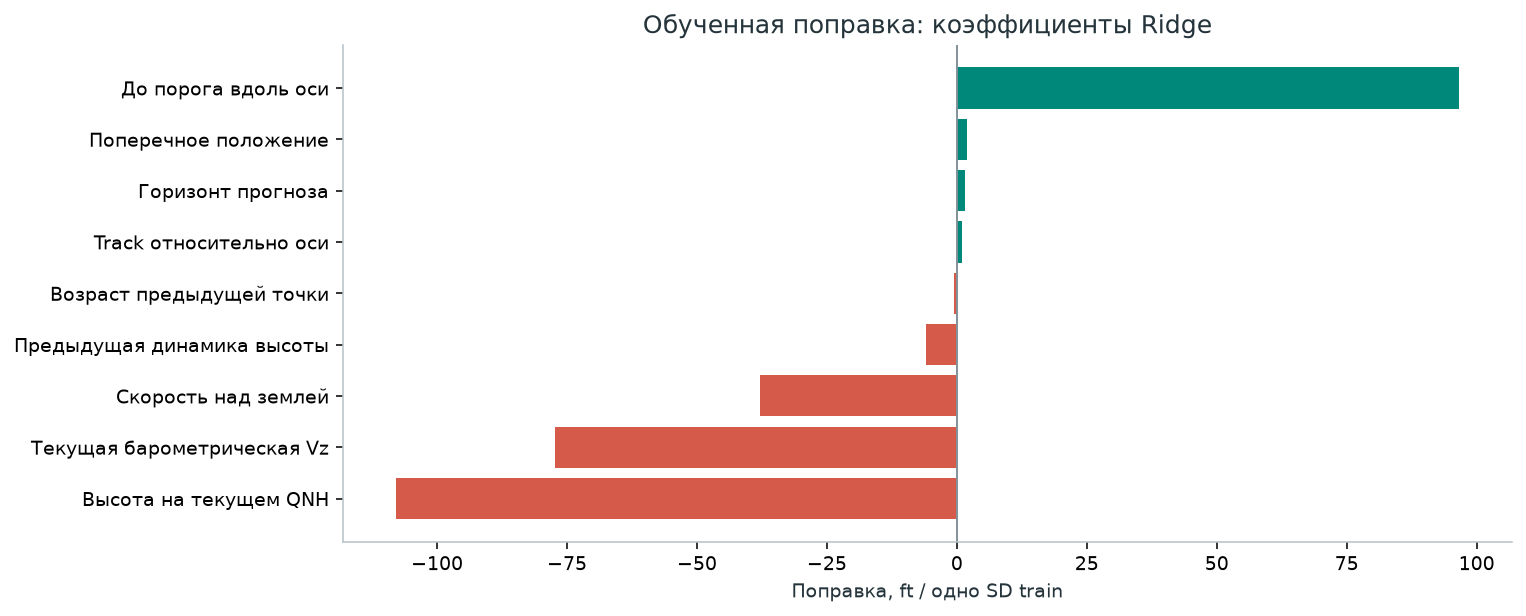

In [9]:
# Сохраняем все коэффициенты и масштабирование для воспроизведения прогноза
coefficients = pd.DataFrame({'feature': FEATURES,
    'coefficient_ft_per_train_sd': selected_model.named_steps['ridge'].coef_,
    'train_mean': selected_model.named_steps['scale'].mean_,
    'train_sd': selected_model.named_steps['scale'].scale_})
coefficients.to_csv(REPORTS / '04_ridge_coefficients.csv', index=False)
comparison = pd.concat([train_metrics.assign(split='train'),
    validation_metrics.assign(split='validation'), test_metrics.assign(split='test')], ignore_index=True)
table(comparison[['split', 'model', 'events', 'macro_mae_ft', 'macro_rmse_ft']])
names = {'height_ft': 'Высота на текущем QNH', 'vertical_rate_fps': 'Текущая барометрическая Vz',
    'past_height_rate_fps': 'Предыдущая динамика высоты', 'speed_knots': 'Скорость над землей',
    'distance_m': 'До порога вдоль оси', 'lateral_m': 'Поперечное положение',
    'heading_error_deg': 'Track относительно оси', 'past_gap_s': 'Возраст предыдущей точки',
    'horizon_s': 'Горизонт прогноза'}
plot_coeff = coefficients.sort_values('coefficient_ft_per_train_sd')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(plot_coeff.feature.map(names), plot_coeff.coefficient_ft_per_train_sd,
        color=[RED if value < 0 else GREEN for value in plot_coeff.coefficient_ft_per_train_sd])
ax.axvline(0, color=GREY, lw=1)
ax.set(title='Обученная поправка: коэффициенты Ridge', xlabel='Поправка, ft / одно SD train')
fig.tight_layout()
savefig(fig, '04_ridge_coefficients')

### Авиационная интерпретация обученной поправки

Модель может уменьшать ошибку типичного снижения за счет геометрической связи высоты и удаления, одновременно ослабляя влияние текущей Vz. Это проверяемое свойство уравнения прогноза, а не доказательство захвата глиссады или причинного влияния признаков.

Такая поправка может сглаживать отклонения от обычного профиля. До проверки на подтвержденных нестандартных заходах и уходах ее нельзя автоматически использовать как основу баллов риска.

In [10]:
# Вычисляем прямой коэффициент текущей Vz при фиксированном горизонте 30 с
vz_index = FEATURES.index('vertical_rate_fps')
ridge_vz_coefficient = (selected_model.named_steps['ridge'].coef_[vz_index]
                       / selected_model.named_steps['scale'].scale_[vz_index])
effective_vz_coefficient = protocol['nominal_horizon_s'] + ridge_vz_coefficient
panel('Как меняется влияние текущей вертикальной скорости',
    f'При фиксированных остальных признаках и горизонте 30 с коэффициент при Vz равен '
    f'{effective_vz_coefficient:.2f} с вместо 30 с у baseline. '
    'Обученная поправка существенно ослабляет прямой вклад текущей Vz; '
    'это требует отдельной проверки при отклонении от обычного снижения.')

## 09 Разбор конкретных заходов

Правило выбора примеров задано заранее: первый и последний test-кандидат по времени суток и кандидат с наибольшей ошибкой физического baseline. При совпадении берется следующий кандидат по времени. Это диагностические иллюстрации, не отдельный эксперимент.

Серые точки показывают наблюдаемую цель на QNH момента прогноза. Красный и зеленый прогнозы нанесены на время target, примерно на 30 с позже исходного наблюдения. Обозначения кандидатов сохранены для связи с таблицами. Полная кривая наблюдений приведена только как ретроспективный контекст.

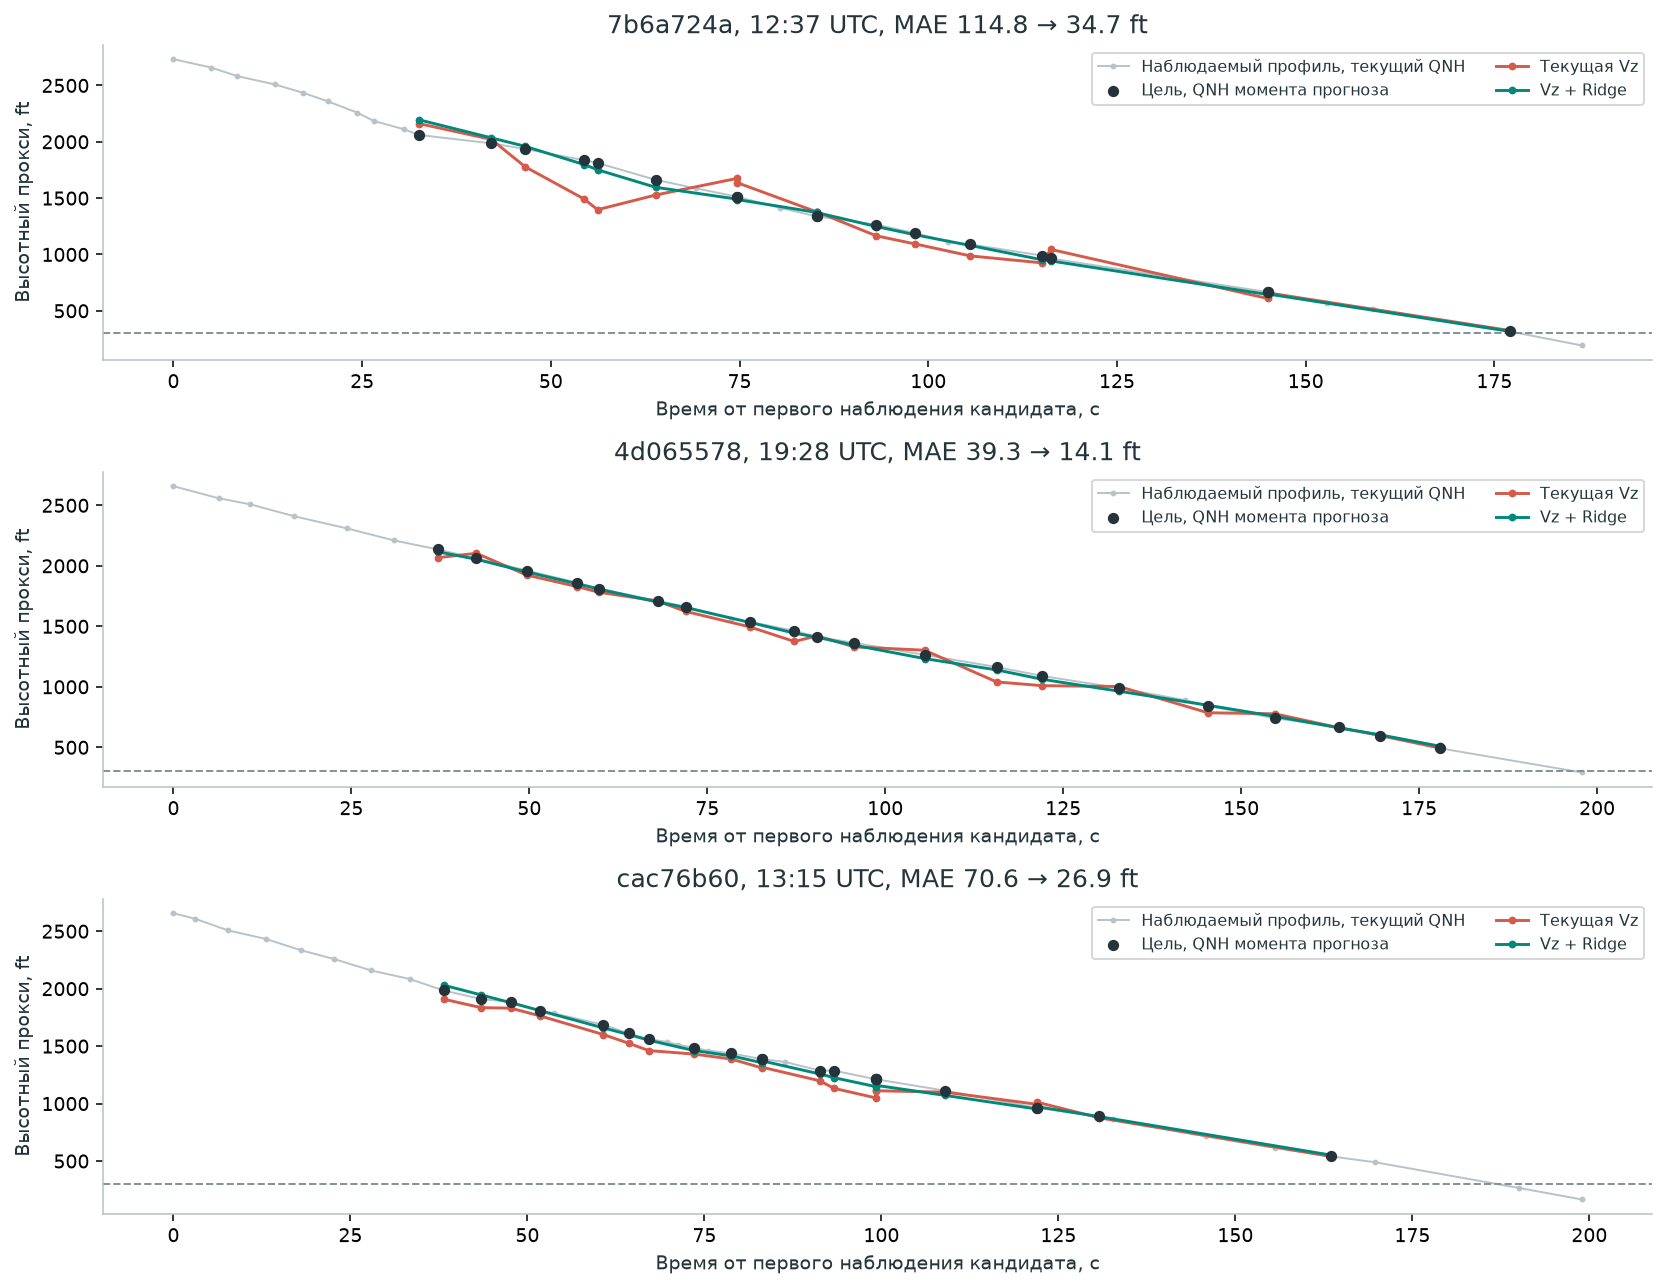

In [11]:
# Разбираем случаи по фиксированному правилу без отбора по выигрышу Ridge
ordered_ids = cohort.loc[cohort.split.eq('test')].sort_values('start_time').event_id.tolist()
worst_baseline = wide['Constant vertical rate'].idxmax()
case_ids = list(dict.fromkeys([ordered_ids[0], ordered_ids[-1], worst_baseline]))
for event_id in ordered_ids:
    if len(case_ids) >= 3:
        break
    if event_id not in case_ids:
        case_ids.append(event_id)
case_rows = []
fig, axes = plt.subplots(len(case_ids), 1, figsize=(12, 3.1 * len(case_ids)), squeeze=False)
for ax, event_id in zip(axes[:, 0], case_ids):
    candidate = cohort.loc[cohort.event_id.eq(event_id)].iloc[0]
    observed = points.loc[points.event_id.eq(event_id)].sort_values('time')
    subset = test.loc[test.event_id.eq(event_id)].sort_values('target_time')
    start = float(candidate.start_time)
    ax.plot(observed.time - start, observed.height_proxy_ft, color='#B7C3C8', lw=1,
            marker='.', ms=4, label='Наблюдаемый профиль, текущий QNH')
    ax.scatter(subset.target_time - start, subset.target_height_ft, color=INK, s=23,
               label='Цель, QNH момента прогноза', zorder=4)
    ax.plot(subset.target_time - start, subset.baseline_ft, color=RED, lw=1.5,
            marker='o', ms=3, label='Текущая Vz')
    ax.plot(subset.target_time - start, subset.ridge_ft, color=GREEN, lw=1.5,
            marker='o', ms=3, label='Vz + Ridge')
    ax.axhline(300, color=GREY, ls='--', lw=1)
    time_label = candidate.start_utc.strftime('%H:%M UTC')
    ax.set(title=f'{event_id[:8]}, {time_label}, '
           f'MAE {wide.loc[event_id, "Constant vertical rate"]:.1f} → '
           f'{wide.loc[event_id, "Ridge correction"]:.1f} ft',
           xlabel='Время от первого наблюдения кандидата, с', ylabel='Высотный прокси, ft')
    ax.legend(fontsize=8, ncol=2)
    case_rows.append({'event_id': event_id, 'start_utc': candidate.start_utc.isoformat(),
        'baseline_mae_ft': float(wide.loc[event_id, 'Constant vertical rate']),
        'ridge_mae_ft': float(wide.loc[event_id, 'Ridge correction'])})
fig.tight_layout()
savefig(fig, '04_approach_cases')
pd.DataFrame(case_rows).to_csv(REPORTS / '04_case_selection.csv', index=False)

## 10 NOTAM 09L: документ и границы применимости

### Найденное сообщение A3237/26

В [опубликованном тексте NOTAM](https://notamify.com/notams/LFPG/a1750904-201a-40ab-a66d-d70265c0bceb) указано обслуживание ILS направлений **09L и 27R**. Период B/C: **26.05.2026 11:30 UTC – 27.05.2026 15:30 UTC**; расписание D: **ежедневно 11:30–15:30 UTC**. Это два отдельных четырехчасовых окна.

Короткий фрагмент поля E:

> ILS RWY 09L 109.350MHZ AND ILS RWY 27R 110.350MHZ U/S : MAINTENANCE, DO NOT USE POSSIBLE FALSE INDICATION.

**Авиационный смысл:** ILS недоступны на время обслуживания, их использование запрещено, возможны ложные показания. Это ограничение наведения; сообщение само по себе не объявляет закрытие ВПП. Совпадение ADS-B траектории с осью и расчетным профилем не подтверждает исправность ILS и фактический захват глиссады.

Источник – перепубликация Notamify, проверенная 13.10.2026. Официальный оригинал и цепочка замены/отмены не получены. Срок по полю C закончился. [Приложение с полями и разбором](../reports/04_NOTAM_09L_A3237-26.md), [происхождение в JSON](../reports/04_notam_09l_example.json).

**Этот NOTAM относится к маю 2026 и не применим к 37 кандидатам за 15.01.2025.** Он служит документальным примером для 09L и не входит в признаки или отбор.

### Исторический комплект на дату пилота

**Запрошен комплект, действовавший 15.01.2025. Оригинальный текст пока не получен.**

В приложение включены [статус и источники запроса](../reports/04_NOTAM_09L_2025-01-15.md) и [машиночитаемый журнал](../reports/04_notam_09l_status.json). Это журнал проверки документов; архивный NOTAM или PIB в нем отсутствует. Отсутствие документа не доказывает отсутствия ограничений.

[Официальный SIA](https://www.sia.aviation-civile.gouv.fr/faqs) направляет поиск NOTAM в SOFIA. В [руководстве SOFIA от 13.11.2025, стр. 2 и 5](https://sofia-briefing.aviation-civile.gouv.fr/content/sofia/datas/admin/medias/FAQ/Je%20travaille%20%C3%A0%20la%20DGAC/Je%20suis%20informateur%20a%C3%A9ronautique%20et%20je%20souhaite%20consulter%20des%20NOTAM.pdf) указан срок доступа к истекшим сообщениям – 95 дней после окончания действия. Полный комплект за январь 2025 через этот интерфейс сейчас не восстановлен. Коммерческий архив [Notamify](https://notamify.com/notam-v2-endpoints) требует авторизованного доступа.

Найденный [SUP AIP AIRAC 013/25](https://www.sia.aviation-civile.gouv.fr/media/store/documents/file/l/f/lf_sup_a_2025_013_fr.pdf) касается закрытия 09L/27R в апреле–мае 2025. Он опубликован после дня пилота, не является январским NOTAM и исключен из интерпретации этих траекторий.

До получения оригинального комплекта историческая доступность ILS, эксплуатационное состояние ВПП и временные изменения порога остаются непроверенными. Номинальная геометрия взята из снимка OurAirports до даты пилота. Порог 300 ft является исследовательским прокси и не подменяет DA/H или MDA/H процедуры.

In [12]:
# Показываем поля найденного сообщения и отдельно проверяем его дату
table(pd.DataFrame([
    {'Поле': 'Номер', 'Значение': notam_example['notice_id']},
    {'Поле': 'Q', 'Значение': notam_example['q_line']},
    {'Поле': 'A', 'Значение': notam_example['airport']},
    {'Поле': 'B', 'Значение': notam_example['validity_start_utc']},
    {'Поле': 'C', 'Значение': notam_example['validity_end_utc']},
    {'Поле': 'D', 'Значение': 'Ежедневно 11:30–15:30 UTC'},
    {'Поле': 'E, смысл', 'Значение': notam_example['meaning_ru']}]))
notice_start = pd.Timestamp(notam_example['validity_start_utc'])
notice_end = pd.Timestamp(notam_example['validity_end_utc'])
pilot_start = pd.Timestamp(protocol['date'], tz='UTC')
pilot_end = pilot_start + pd.Timedelta(days=1)
overlaps_pilot = notice_start < pilot_end and notice_end > pilot_start
assert not overlaps_pilot and not notam_example['applicable_to_2025_01_15_pilot']
assert not notam_example['used_in_model_features']
panel('Документ найден, даты разграничены',
      f"{notam_example['notice_id']}: май 2026; пилот: январь 2025. "
      'Временного пересечения нет; условия этого сообщения не перенесены на кандидатов')

# Включаем в выполненный ноутбук проверяемый статус исторического приложения
document_table = pd.DataFrame([
    {'Проверка': 'Исторический оригинал NOTAM / PIB', 'Статус': 'Не получен'},
    {'Проверка': 'Полнота действовавшего комплекта 15.01.2025', 'Статус': 'Не подтверждена'},
    {'Проверка': 'Современные NOTAM перенесены на старые полеты', 'Статус': 'Нет'},
    {'Проверка': 'NOTAM включены в признаки обучения', 'Статус': 'Нет'},
    {'Проверка': 'Отсутствие ограничений заявлено', 'Статус': 'Нет'}])
table(document_table)
assert not notam['complete_active_set_verified'] and not notam['notam_features_used']

Поле,Значение
Номер,A3237/26
Q,LFFF/QICAS/I /NBO/A /000/999/4901N00233E005
A,LFPG
B,2026-05-26T11:30:00Z
C,2026-05-27T15:30:00Z
D,Ежедневно 11:30–15:30 UTC
"E, смысл","Обслуживание ILS 09L и 27R: системы недоступны, использование запрещено, возможны ложные показания"


Проверка,Статус
Исторический оригинал NOTAM / PIB,Не получен
Полнота действовавшего комплекта 15.01.2025,Не подтверждена
Современные NOTAM перенесены на старые полеты,Нет
NOTAM включены в признаки обучения,Нет
Отсутствие ограничений заявлено,Нет


## 11 Результат и границы интерпретации

Ниже вывод формируется из фактически выполненного эксперимента. Выигрыш модели оценивается относительно продолжения текущей Vz, а не относительно постоянной высоты или другого слабого baseline.

Пилот ограничен одним днем, 37 наблюдаемыми кандидатами и одной ВПП. Отбор до 300 ft исключает часть неполных траекторий и возможных ранних уходов. Проверяемый target – барометрическое наблюдение архива, а не независимое измерение истинной высоты. Проверка на другом дне необходима до переноса выводов.

Результат этого этапа – воспроизводимый эксперимент прогноза динамики. Баллы риска, пороги нестабильности, фактический GoA и переносимость на Хитроу здесь не обучаются и не подтверждаются.

In [13]:
# Формулируем вывод по результату, сохраняя baseline при отсутствии убедительного выигрыша
lower = interval['conditional_interval_2_5_ft']
upper = interval['conditional_interval_97_5_ft']
if improvement_pct > 0 and upper < 0:
    conclusion = 'Поправка улучшила прогноз в этой контрольной группе; требуется независимый день'
elif improvement_pct > 0:
    conclusion = 'Наблюдаемое улучшение неустойчиво по малой контрольной группе; baseline сохраняется'
else:
    conclusion = 'Поправка не улучшила прогноз на test; физический baseline сохраняется'
panel('Вывод эксперимента', f'{conclusion}<br>Macro MAE: {baseline_mae:.2f} → {ridge_mae:.2f} ft; '
      f'изменение качества {improvement_pct:+.1f}%.<br>'
      f'Парная разность Ridge − baseline: {interval["ridge_minus_baseline_mae_ft"]:+.2f} ft; '
      f'условный интервал [{lower:+.2f}; {upper:+.2f}] ft.',
      GREEN if improvement_pct > 0 else RED)

# Фиксируем входы, конфигурацию, среду и результат как воспроизводимую цепочку
def digest(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

environment = {'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'matplotlib': plt.matplotlib.__version__,
    'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__, 'joblib': joblib.__version__}
(REPORTS / '04_environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
(REPORTS / '04_training_protocol.json').write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding='utf-8')
manifest = {'date': protocol['date'], 'runway': '09L', 'candidate_events': len(cohort),
    'aircraft': cohort.icao24.nunique(), 'observed_pairs': len(examples),
    'split': counts.to_dict(orient='records'), 'selected_alpha': selected_alpha,
    'baseline_macro_mae_ft': baseline_mae, 'ridge_macro_mae_ft': ridge_mae,
    'improvement_pct': improvement_pct, 'bootstrap': interval, 'conclusion': conclusion,
    'protocol_sha256': digest(protocol_path),
    'inputs_sha256': {str(path.relative_to(BASE)).replace(chr(92), '/'): digest(path)
        for path in [DATA / 'event_candidate_points.parquet', REPORTS / '03_event_candidates.csv',
                     REPORTS / '03_runway_geometry.csv', REPORTS / '03_geometry_sources.json']},
    'implementation_sha256': {str(path.relative_to(PROJECT)).replace(chr(92), '/'): digest(path)
        for path in [PROJECT / 'scripts/lfpg_training.py', PROJECT / 'scripts/build_lfpg_training_notebook.py',
                     PROJECT / 'scripts/execute_notebook.py']},
    'model_sha256': digest(ARTIFACTS / 'altitude_residual_ridge.joblib'),
    'examples_sha256': digest(DATA / 'training_04_examples.parquet'),
    'target_interpolation': False, 'forecast_horizon': 'observed 30 +/- 3 seconds',
    'future_weather_used': False, 'split_is_chronological': False,
    'test_used_for_tuning': False, 'glideslope_capture_verified': False,
    'true_height_verified': False, 'historical_notam_verified': False, 'goaround_model_trained': False}
(REPORTS / '04_training_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
result_text = chr(10).join([
    '# LFPG 09L – обучение прогноза высотной динамики', '',
    f'37 кандидатов, 35 бортов, {len(examples)} пар наблюдений за 15.01.2025. '
    'Горизонт 30 ± 3 с, без интерполяции; контрольный прокси 300 ft.', '',
    f'{conclusion}. Test macro MAE: {baseline_mae:.2f} ft для текущей Vz и {ridge_mae:.2f} ft '
    f'с поправкой Ridge; изменение качества {improvement_pct:+.1f}%. '
    f'Alpha={selected_alpha:g} выбрана по validation.', '',
    f'Условный парный интервал Ridge − baseline [{lower:.2f}; {upper:.2f}] ft, '
    'bootstrap целыми бортами. Вывод относится к одной контрольной группе одного дня.', '',
    'Оригинальные исторические NOTAM / PIB не получены. '
    'Статус и источники: [приложение](04_NOTAM_09L_2025-01-15.md). '
    'Найден [пример A3237/26](04_NOTAM_09L_A3237-26.md) за май 2026; '
    'к январскому пилоту он не применим. '
    'GoA, истинная высота и фактический захват ILS не подтверждены.', ''])
(REPORTS / '04_research_result.md').write_text(result_text, encoding='utf-8')
print('Протокол, модель, парные прогнозы, таблицы, рисунки и манифест сохранены')

Протокол, модель, парные прогнозы, таблицы, рисунки и манифест сохранены


## 12 Следующий проверяемый шаг

Сохранить этот эксперимент без изменения признаков по результатам test. Получить оригинальные NOTAM/PIB на дату пилота и проверить историческую геометрию. Затем воспроизвести замороженную модель на другом дне LFPG; после этого оценивать переносимость на EGLL.

Для исследования фактических уходов нужен отдельный набор подтвержденных исходов, включая ранние и неполные траектории. Эти 37 кандидатов не являются сбалансированной выборкой GoA и посадок.

**Воспроизведение:** выполнить ячейки последовательно из `airports/LFPG/notebooks` либо запустить из корня проекта `python scripts/build_lfpg_training_notebook.py`. Данные и модель хранятся локально в игнорируемых `data` и `artifacts`; публичные отчеты содержат протокол, агрегаты, рисунки и контрольные суммы.

**Источники данных и семантики:** [ADSB.lol, архив 2025](https://github.com/adsblol/globe_history_2025), [формат trace readsb](https://github.com/wiedehopf/readsb/blob/dev/README-json.md), [OurAirports](https://ourairports.com/data/), [исторический снимок геометрии](https://github.com/davidmegginson/ourairports-data/tree/121faf552580e224617e23867e491f8b5b7bc0f9), [IEM METAR](https://mesonet.agron.iastate.edu/request/download.phtml?network=FR__ASOS), [FAA: барометрическая высота ADS-B](https://www.faa.gov/documentLibrary/media/Advisory_Circular/AC%2020-165.pdf), [модель стандартной атмосферы](https://ntrs.nasa.gov/api/citations/19930090991/downloads/19930090991.pdf).

Архив ADSB.lol опубликован под ODbL 1.0. Производные таблицы и рисунки этого пилота ссылаются на него и на манифест происхождения этапа 02; сырые данные исключены из Git.